In [ ]:
#imports
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
#File path
folder = Path("/content/drive/MyDrive/Hospital_Data/OG_data")

# Exclude previously generated merged files
excluded_files = []
files = sorted([f for f in folder.glob("*.csv") if f.name not in excluded_files])

#columns to be extracted -> included the ones highlghted in the excel sheet
keep_cols = [
    "FAC_NO",
    "FAC_NAME",
    "BEG_DATE",
    "END_DATE",
    "DAY_PER",
    "DATA_IND",
    "AUDIT_IND",
    "COUNTY",
    "HSA",
    "HFPA",
    "TYPE_CNTRL",
    "TYPE_CARE",
    "TYPE_HOSP",
    "TEACH_RURL",
    "PHONE",
    "ADDRESS",
    "CITY",
    "ZIP_CODE",
    "CEO",
    "CEO_TITLE",
    "WEB_SITE",
    "OWNER",
    "DAY_TOT",
    "DIS_TOT",
    "DIS_NURSRY",
    "VIS_TOT",
    "VIS_ER",
    "VIS_CLIN",
    "VIS_REF_OP",
    "OP_MIN_IP",
    "OP_MIN_OP",
    "SURG_IP",
    "SURG_OP",
    "NAT_0BIRTHS",
    "C_SECTIONS",
    "EXP_DLY",
    "EXP_AMB",
    "EXP_ANC",
    "EXP_PIP",
    "EXP_POP",
    "EXP_RES",
    "EXP_ED",
    "EXP_GEN",
    "EXP_FISC",
    "EXP_ADM",
    "EXP_UNASSG",
    "EXP_SAL",
    "EXP_BEN",
    "EXP_PHYS",
    "EXP_OTHPRO",
    "EXP_SUPP",
    "EXP_PURCH",
    "EXP_DEPRE",
    "EXP_LEASES",
    "EXP_INSUR",
    "EXP_INTRST",
    "EXP_OTH",
    "HOSP_FTE",
    "NURS_FTE",
    "PROD_HRS",
    "NON_PRD_HR",
    "PAID_HRS",
    "MED_STAFF",
    "STDNT_FTE",
    "PRD_HR_DLY",
    "PRD_HR_AMB",
    "PRD_HR_ANC",
    "PRD_HR_ED",
    "PRD_HR_GEN",
    "PRD_HR_FIS",
    "PRD_HR_ADM",
    "PRD_HR_NON",
    "PD_HR_DLY",
    "PD_HR_AMB",
    "PD_HR_ANC",
    "PD_HR_ED",
    "PD_HR_GEN",
    "PD_HR_FIS",
    "PD_HR_ADM",
    "PD_HR_NON"
]

# store each cleaned dataframe
dfs = []
# store hospital ID sets from each file
hospital_sets = []

for f in files:
    df = pd.read_csv(f)

    # keep only columns that exist
    cols = [c for c in keep_cols if c in df.columns]
    df = df[cols].copy()

    # make sure hospital_id is consistent
    df["FAC_NO"] = df["FAC_NO"].astype(str).str.strip()

    dfs.append(df)
    hospital_sets.append(set(df["FAC_NO"].dropna().unique()))

# hospitals present in every file
common_hospitals = set.intersection(*hospital_sets)

# filter each dataframe to only those hospitals
filtered_dfs = [
    df[df["FAC_NO"].isin(common_hospitals)].copy()
    for df in dfs
]

# combine into one dataset
merged = pd.concat(filtered_dfs, ignore_index=True)

print("Hospitals in every file:", len(common_hospitals))
print("Rows in merged file:", len(merged))

Hospitals in every file: 357
Rows in merged file: 1805


In [ ]:
#Null values
print("Null values in the merged dataset:")
display(merged.isnull().sum())

Null values in the merged dataset:


,0
FAC_NO,0
FAC_NAME,0
BEG_DATE,0
END_DATE,0
DAY_PER,0
...,...
PD_HR_GEN,0
PD_HR_FIS,0
PD_HR_ADM,0
PD_HR_NON,359


In [ ]:
#Panel of Hospitals
'''
unique_hospitals = merged['FAC_NAME'].unique()
print(unique_hospitals)
'''

"\nunique_hospitals = merged['FAC_NAME'].unique()\nprint(unique_hospitals)\n"

In [ ]:
#Defining Expenses

# Define patient expense columns
patient_expense_cols = [
    'EXP_DLY',
    'EXP_AMB',
    'EXP_ANC',
    'EXP_PIP',
    'EXP_POP'
]

# Define overhead expense columns
overhead_expense_cols = [
    'EXP_RES',
    'EXP_ED',
    'EXP_GEN',
    'EXP_FISC',
    'EXP_ADM',
    'EXP_UNASSG'
]


In [ ]:
#Creating year column
hospital_data_df = merged.copy()

# Ensure 'END_DATE' is in datetime format, handling mixed formats and coercing errors
hospital_data_df['END_DATE'] = pd.to_datetime(hospital_data_df['END_DATE'], format='mixed', errors='coerce')

# Assign 'YEAR' based on 'END_DATE'
hospital_data_df['YEAR'] = hospital_data_df['END_DATE'].dt.year

print("New DataFrame 'hospital_data_df' created with 'YEAR' column based on END_DATE.")
display(hospital_data_df.head())

New DataFrame 'hospital_data_df' created with 'YEAR' column based on END_DATE.


,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_DLY,PD_HR_AMB,PD_HR_ANC,PD_HR_ED,PD_HR_GEN,PD_HR_FIS,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,YEAR
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,1276968,786518,619394,282217,892239,407129,482813,NaN,NaN,2004
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,245518,43688,203882,0,152714,72787,107765,NaN,NaN,2004
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,421982,33666,200830,0,123190,65041,101170,NaN,NaN,2004
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,1787592,227360,1203534,6377,805001,172990,388515,NaN,NaN,2004
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,1268124,158076,906146,340026,690224,176223,231959,NaN,NaN,2004


In [ ]:
from pathlib import Path
import pandas as pd

folder2 = Path("/content/drive/MyDrive/Hospital_Data/PIVOT_data")

files = [
    "hafd2004pivot.xls",
    "hafd2009pivot.xls",
    "hafd2014pivot.xls",
    "hafd2019pivot.xls",
    "hafd2024pivot.xlsm",
]

pieces = []

for fname in files:
    fp = folder2 / fname
    df = pd.read_excel(fp, sheet_name="Data")

    # Clean column names
    df.columns = df.columns.str.strip().str.upper()

    # Create YEAR
    df["END_DATE"] = pd.to_datetime(df["END_DATE"], errors="coerce", format="mixed")
    df["YEAR"] = df["END_DATE"].dt.year

    # Keep only needed columns
    keep_cols = ["FAC_NO", "YEAR", "ADJ PAT DAYS"]
    df = df[[c for c in keep_cols if c in df.columns]].copy()

    # Rename to cleaner format
    df = df.rename(columns={"ADJ PAT DAYS": "ADJ_PAT_DAYS"})

    pieces.append(df)

# Combine all years
adj_data = pd.concat(pieces, ignore_index=True)

# Remove duplicates
adj_data = adj_data.drop_duplicates(subset=["FAC_NO", "YEAR"])

# Clean existing dataframe columns
hospital_data_df.columns = hospital_data_df.columns.str.strip().str.upper()


print(hospital_data_df[["FAC_NO", "YEAR"]].dtypes)
print(adj_data[["FAC_NO", "YEAR"]].dtypes)

FAC_NO    object
YEAR       int32
dtype: object
FAC_NO    int64
YEAR      int32
dtype: object


In [ ]:
hospital_data_df["FAC_NO"] = hospital_data_df["FAC_NO"].astype(str).str.strip()
adj_data["FAC_NO"] = adj_data["FAC_NO"].astype(str).str.strip()

hospital_data_df["YEAR"] = hospital_data_df["YEAR"].astype("Int64")
adj_data["YEAR"] = adj_data["YEAR"].astype("Int64")

final_df = hospital_data_df.merge(
    adj_data,
    on=["FAC_NO", "YEAR"],
    how="left"
)

display(final_df.head())

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_AMB,PD_HR_ANC,PD_HR_ED,PD_HR_GEN,PD_HR_FIS,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,YEAR,ADJ_PAT_DAYS
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,786518,619394,282217,892239,407129,482813,NaN,NaN,2004,144932.301653
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,43688,203882,0,152714,72787,107765,NaN,NaN,2004,29701.648973
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,33666,200830,0,123190,65041,101170,NaN,NaN,2004,49131.786996
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,227360,1203534,6377,805001,172990,388515,NaN,NaN,2004,191236.749183
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,158076,906146,340026,690224,176223,231959,NaN,NaN,2004,118688.587429


In [ ]:
# Calculate total patient expenses for each record in merged_with_end_year
final_df['Patient_Expenses'] = final_df[patient_expense_cols].sum(axis=1)

# Calculate total overhead expenses for each record in merged_with_end_year
final_df['Overhead_Expenses'] = final_df[overhead_expense_cols].sum(axis=1)
# Group by YEAR (derived from END_DATE) and sum patient and overhead expenses
yearly_expenses_end_date = final_df.groupby('YEAR')[['Patient_Expenses', 'Overhead_Expenses']].sum().reset_index()

# Calculate the total combined expenses for patient and overhead
yearly_expenses_end_date['Total_Combined_Expenses'] = yearly_expenses_end_date['Patient_Expenses'] + yearly_expenses_end_date['Overhead_Expenses']

# Calculate the percentage of Patient Expenses
yearly_expenses_end_date['Patient_Expense_Percentage'] = (yearly_expenses_end_date['Patient_Expenses'] / yearly_expenses_end_date['Total_Combined_Expenses']) * 100

# Calculate the percentage of Overhead Expenses
yearly_expenses_end_date['Overhead_Expense_Percentage'] = (yearly_expenses_end_date['Overhead_Expenses'] / yearly_expenses_end_date['Total_Combined_Expenses']) * 100

display(yearly_expenses_end_date[['YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage']])

,YEAR,Patient_Expense_Percentage,Overhead_Expense_Percentage
0,2004,60.890059,39.109941
1,2009,61.561269,38.438731
2,2014,59.017496,40.982504
3,2019,59.423566,40.576434
4,2024,59.983245,40.016755


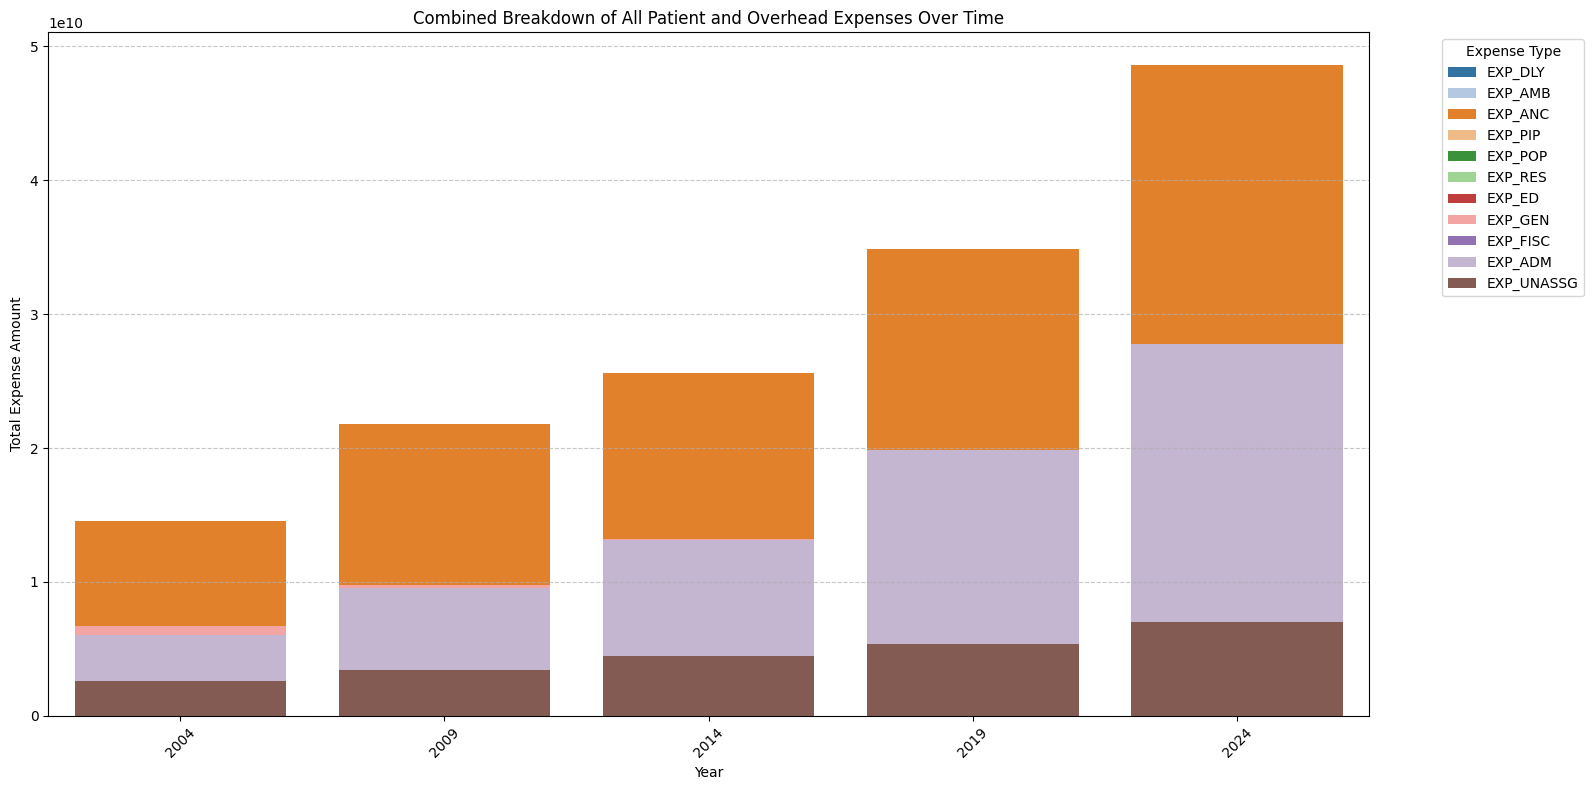

In [ ]:
# Combine all expense columns
all_expense_cols = patient_expense_cols + overhead_expense_cols

# Prepare data for the combined breakdown
all_expenses_breakdown = final_df[['YEAR'] + all_expense_cols].groupby('YEAR')[all_expense_cols].sum().reset_index()
all_expenses_melted = all_expenses_breakdown.melt(id_vars=['YEAR'], var_name='Expense_Type', value_name='Amount')

# Set the figure size
plt.figure(figsize=(16, 8))

# Create a stacked bar chart for the combined expense breakdown
sns.barplot(x='YEAR', y='Amount', hue='Expense_Type', data=all_expenses_melted, palette='tab20', dodge=False)

plt.title('Combined Breakdown of All Patient and Overhead Expenses Over Time')
plt.xlabel('Year')
plt.ylabel('Total Expense Amount')
plt.legend(title='Expense Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


 Total Operating Expenses by Year:


,YEAR,Patient_Expenses,Overhead_Expenses,Total_Combined_Expenses
0,2004,27811315444,17863325095,45674640539
1,2009,41699538308,26037107213,67736645521
2,2014,50405612824,35002302815,85407915639
3,2019,70766665789,48321887799,119088553588
4,2024,97475421390,65028994522,162504415912


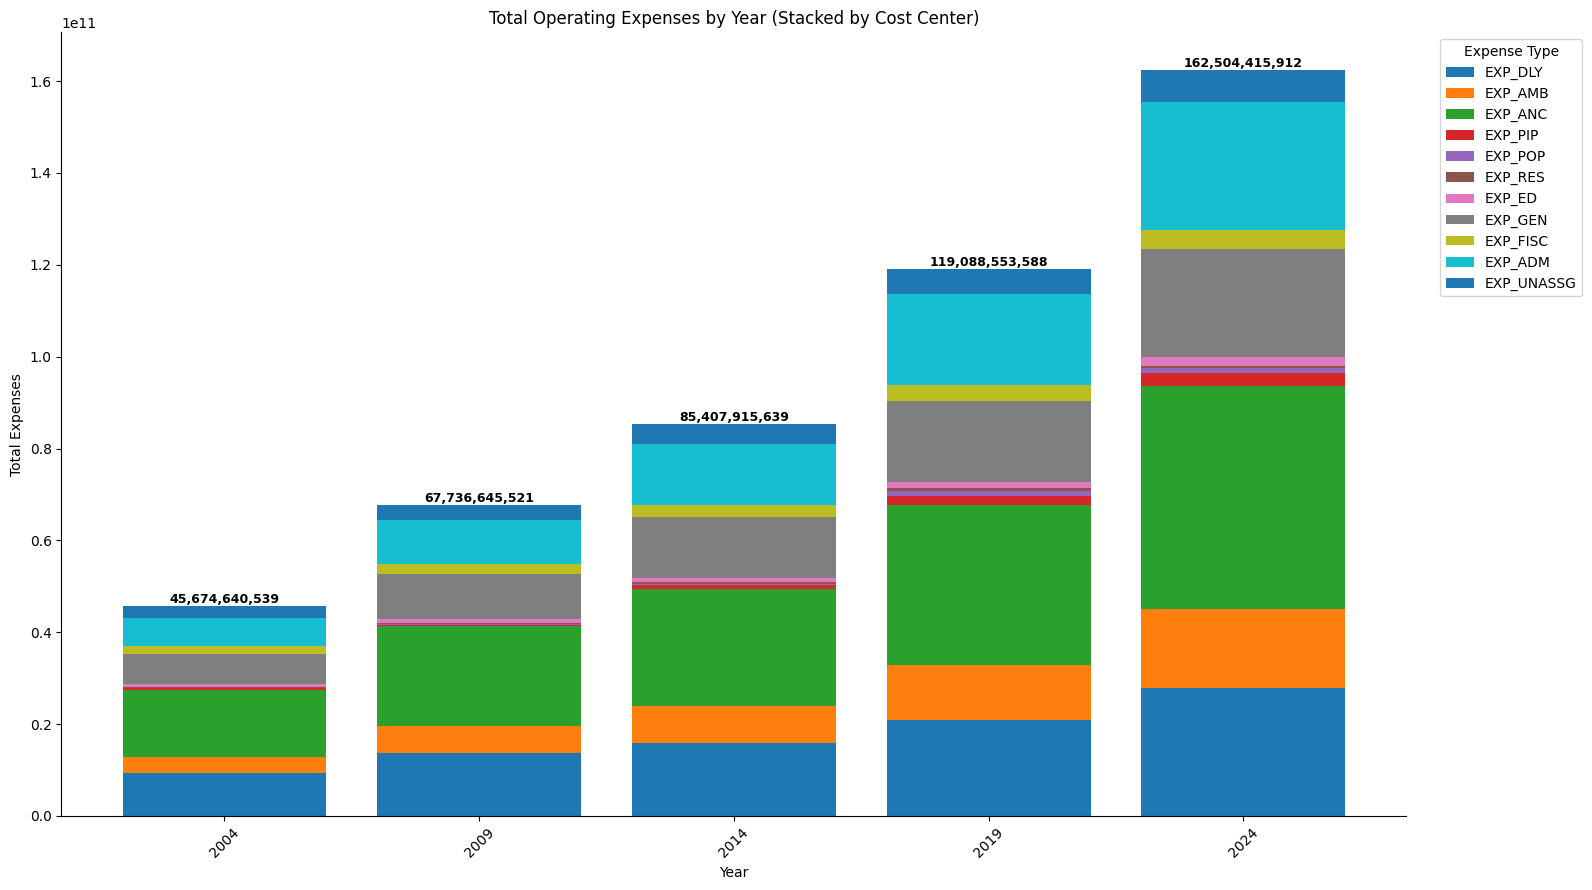

In [ ]:
# Using the predefined all_expense_cols from earlier in the notebook
# all_expense_cols = [
#     "EXP_DLY",    # Daily Hospital Services
#     "EXP_AMB",    # Ambulatory Services
#     "EXP_ANC",    # Ancillary Services
#     "EXP_PIP",    # Purchased Inpatient Services
#     "EXP_POP",    # Purchased Outpatient Services
#     "EXP_RES",    # Research
#     "EXP_ED",     # Education
#     "EXP_GEN",    # General Services
#     "EXP_FISC",   # Fiscal Services
#     "EXP_ADM",    # Administrative Services
#     "EXP_UNASSG"  # Unassigned Costs
# ]

# Keep only valid columns (in case one is missing)
# This step is redundant if all_expense_cols is already correctly defined in the notebook context
# We will use the existing all_expense_cols and filter final_df
valid_expense_cols = [c for c in all_expense_cols if c in final_df.columns]

# --- 3) Sum expenses by year ---
yearly = (
    final_df.groupby("YEAR", as_index=False)[valid_expense_cols]
      .sum()
      .sort_values("YEAR")
)

# Optional: total operating expense per year
yearly["TOTAL_EXP"] = yearly[valid_expense_cols].sum(axis=1)

# --- 4) Plot stacked bar chart ---
fig, ax = plt.subplots(figsize=(16, 9))

bottom = pd.Series([0] * len(yearly), index=yearly.index)

for col in valid_expense_cols:
    ax.bar(yearly["YEAR"].astype(str), yearly[col], bottom=bottom, label=col)
    bottom = bottom + yearly[col]

# --- 5) Add total labels on top of each bar ---
for i, total in enumerate(yearly["TOTAL_EXP"]):
    ax.text(
        i,
        total,
        f"{total:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )
print("\n Total Operating Expenses by Year:")
display(yearly_expenses_end_date[['YEAR', 'Patient_Expenses', 'Overhead_Expenses','Total_Combined_Expenses']])

ax.set_title("Total Operating Expenses by Year (Stacked by Cost Center)")
ax.set_xlabel("Year")
ax.set_ylabel("Total Expenses")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Expense Type")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Based on the new definition:
# Total FTE = HOSP_FTE
# Other FTE = HOSP_FTE - (NURS_FTE + STDNT_FTE)

final_df['Other_FTE'] = final_df['HOSP_FTE'] - (final_df['NURS_FTE'] + final_df['STDNT_FTE'])


print("DataFrame with 'Total_FTE' and 'Other_FTE' columns added:")
display(final_df[['FAC_NO', 'YEAR', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE']].head())

DataFrame with 'Total_FTE' and 'Other_FTE' columns added:


,FAC_NO,YEAR,HOSP_FTE,NURS_FTE,STDNT_FTE,Other_FTE
0,106010846,2004,2168,572,102,1494
1,106010735,2004,382,118,0,264
2,106190017,2004,429,178,0,251
3,106010739,2004,2062,690,0,1372
4,106010937,2004,1599,555,2,1042


In [ ]:
# Calculate AVG_WAGE using EXP_SAL and HOSP_FTE
# Handle potential division by zero for HOSP_FTE
# Since EXP_SAL and HOSP_FTE exist in final_df (merged from merged_with_end_year),
# we should perform this calculation on final_df for consistency with Total_Combined_Expenses.
final_df['AVG_WAGE'] = final_df.apply(lambda row: row['EXP_SAL'] / row['HOSP_FTE'] if row['HOSP_FTE'] != 0 else 0, axis=1)

# Calculate Total_Combined_Expenses at the record level in final_df
# Patient_Expenses and Overhead_Expenses were already computed and added to final_df in cell A15gykSbRWdp.
# Using merged_with_end_year here caused a KeyError as those columns are not present in it.
final_df['Total_Combined_Expenses'] = final_df['Patient_Expenses'] + final_df['Overhead_Expenses']

print("DataFrame with 'AVG_WAGE' and 'Total_Combined_Expenses' columns added to final_df (first 5 rows):")
# Note: 'Other_FTE' was added to 'merged_with_end_year' AFTER 'final_df' was created.
# Therefore, 'final_df' does not contain 'Other_FTE'.
# We need to adjust the columns for display to reflect this.
display_columns = [
    'FAC_NO', 'YEAR', 'EXP_SAL', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE',
    'AVG_WAGE', 'Total_Combined_Expenses'
]
display(final_df[display_columns].head())

# Perform yearly aggregations on final_df for consistency
yearly_expenses_fte = final_df.groupby('YEAR')[['Total_Combined_Expenses', 'HOSP_FTE']].sum().reset_index()
yearly_avg_wage = final_df.groupby('YEAR')['AVG_WAGE'].mean().reset_index()

DataFrame with 'AVG_WAGE' and 'Total_Combined_Expenses' columns added to final_df (first 5 rows):


,FAC_NO,YEAR,EXP_SAL,HOSP_FTE,NURS_FTE,STDNT_FTE,AVG_WAGE,Total_Combined_Expenses
0,106010846,2004,137744075,2168,572,102,63535.089945,323933479
1,106010735,2004,21300626,382,118,0,55760.801047,52241573
2,106190017,2004,18569143,429,178,0,43284.715618,50444188
3,106010739,2004,134753463,2062,690,0,65350.854995,435102594
4,106010937,2004,117317925,1599,555,2,73369.559099,326355826


/tmp/ipykernel_57841/740510498.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='YEAR', y='AVG_WAGE', data=yearly_avg_wage, palette='viridis')


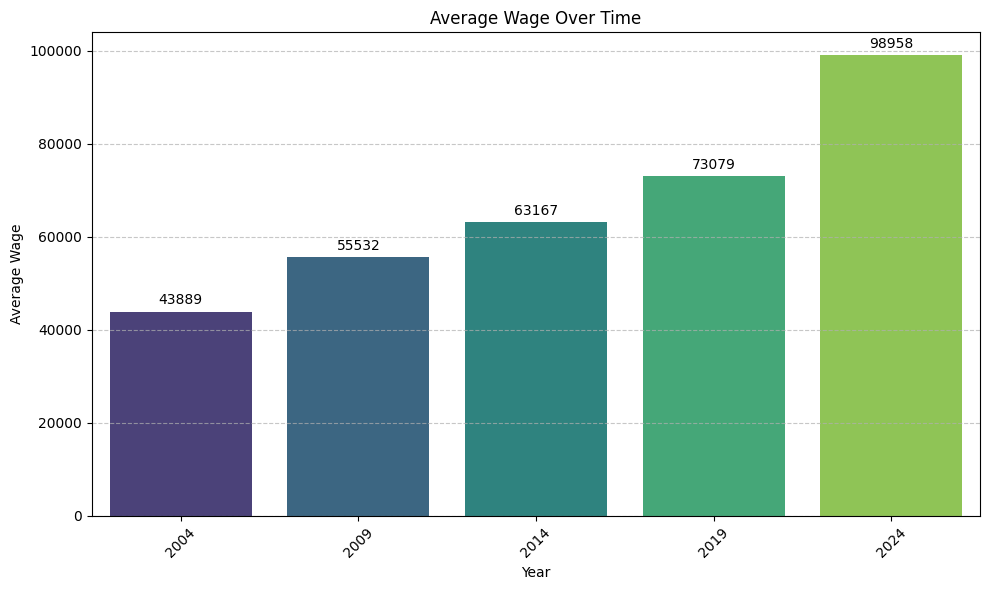

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='YEAR', y='AVG_WAGE', data=yearly_avg_wage, palette='viridis')

plt.title('Average Wage Over Time')
plt.xlabel('Year')
plt.ylabel('Average Wage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

# Add labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', label_type='edge', padding=3)

plt.tight_layout()
plt.show()

Average Wage by Year and Hospital Type:


,YEAR,TYPE_HOSP,AVG_WAGE
0,2004,COMPARABLE,48716.409360
1,2004,KAISER,0.000000
2,2004,LTC EMPHASIS,47218.118295
3,2004,OTHER NON-COMPARABLE,0.000000
4,2004,PHF,16924.869827


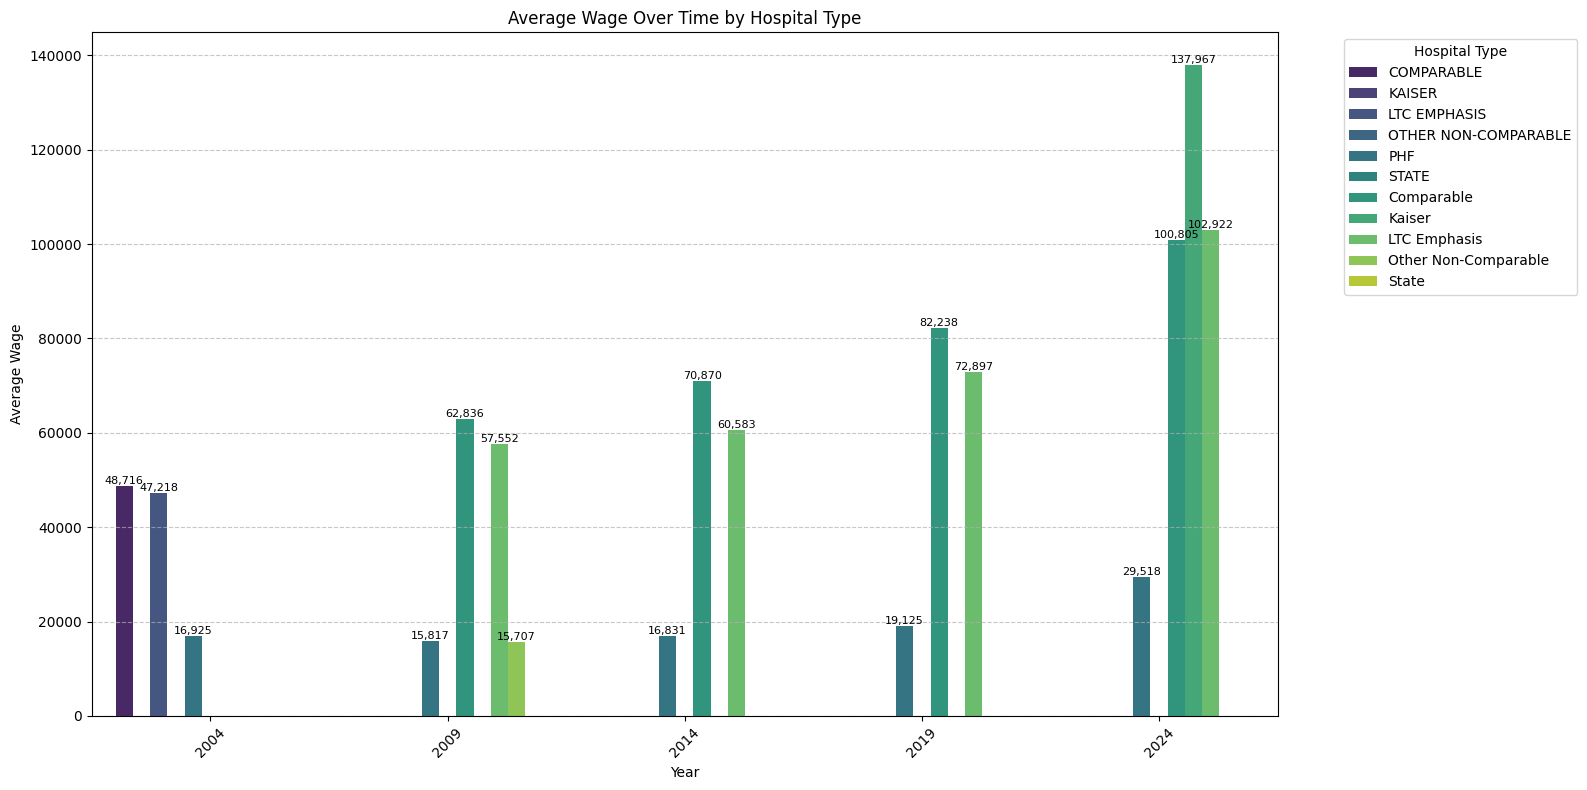

In [ ]:
# Calculate average wage by year and hospital type
yearly_avg_wage_by_type = final_df.groupby(['YEAR', 'TYPE_HOSP'])['AVG_WAGE'].mean().reset_index()

print("Average Wage by Year and Hospital Type:")
display(yearly_avg_wage_by_type.head())

# Plot the average wage by year for each hospital type as a grouped bar chart
plt.figure(figsize=(16, 8)) # Increased figure size for better readability
ax = sns.barplot(x='YEAR', y='AVG_WAGE', hue='TYPE_HOSP', data=yearly_avg_wage_by_type, palette='viridis')

plt.title('Average Wage Over Time by Hospital Type')
plt.xlabel('Year')
plt.ylabel('Average Wage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.legend(title='Hospital Type', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add labels on top of each bar
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0: # Only label non-zero bars
            ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height:,.0f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

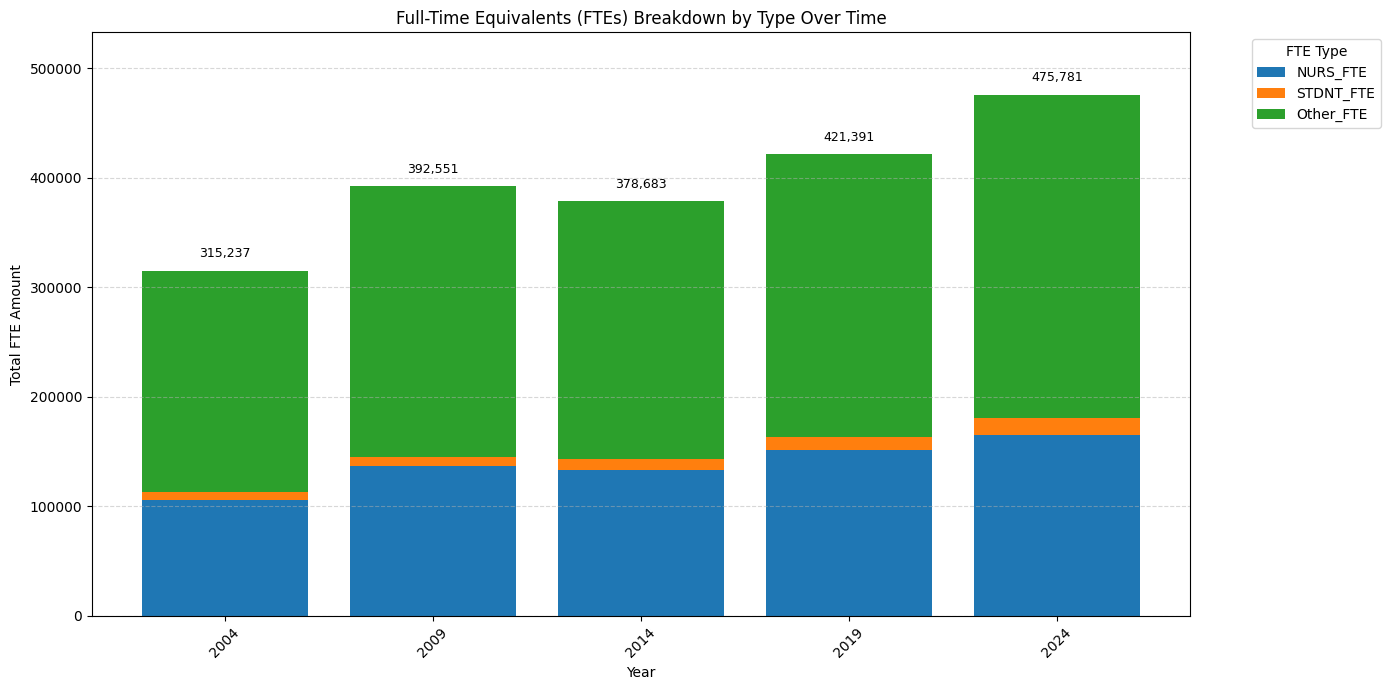

In [ ]:
fte_cols = ['NURS_FTE', 'STDNT_FTE', 'Other_FTE']

# Group by year
fte_breakdown = (
    final_df
    .groupby('YEAR')[fte_cols]
    .sum()
    .reset_index()
    .sort_values('YEAR')
)

years = fte_breakdown['YEAR'].astype(str).tolist()
x = np.arange(len(years))

# Use a numpy array for stacking
bottom = np.zeros(len(fte_breakdown))

fig, ax = plt.subplots(figsize=(14, 7))

for col in fte_cols:
    ax.bar(x, fte_breakdown[col].values, bottom=bottom, label=col)
    bottom += fte_breakdown[col].values

# Total labels on top
yearly_total_ftes = fte_breakdown[fte_cols].sum(axis=1).values
offset = yearly_total_ftes.max() * 0.02

for i, total in enumerate(yearly_total_ftes):
    ax.text(
        x[i],
        total + offset,
        f'{total:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )

ax.set_title('Full-Time Equivalents (FTEs) Breakdown by Type Over Time')
ax.set_xlabel('Year')
ax.set_ylabel('Total FTE Amount')
ax.set_xticks(x)
ax.set_xticklabels(years, rotation=45)
ax.legend(title='FTE Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_ylim(0, yearly_total_ftes.max() * 1.12)

plt.tight_layout()
plt.show()

In [ ]:
final_df.columns

Index(['FAC_NO', 'FAC_NAME', 'BEG_DATE', 'END_DATE', 'DAY_PER', 'DATA_IND',
       'AUDIT_IND', 'COUNTY', 'HSA', 'HFPA', 'TYPE_CNTRL', 'TYPE_CARE',
       'TYPE_HOSP', 'TEACH_RURL', 'PHONE', 'ADDRESS', 'CITY', 'ZIP_CODE',
       'CEO', 'CEO_TITLE', 'WEB_SITE', 'OWNER', 'DAY_TOT', 'DIS_TOT',
       'DIS_NURSRY', 'VIS_TOT', 'VIS_ER', 'VIS_CLIN', 'VIS_REF_OP',
       'OP_MIN_IP', 'OP_MIN_OP', 'SURG_IP', 'SURG_OP', 'C_SECTIONS', 'EXP_DLY',
       'EXP_AMB', 'EXP_ANC', 'EXP_PIP', 'EXP_POP', 'EXP_RES', 'EXP_ED',
       'EXP_GEN', 'EXP_FISC', 'EXP_ADM', 'EXP_UNASSG', 'EXP_SAL', 'EXP_BEN',
       'EXP_PHYS', 'EXP_OTHPRO', 'EXP_SUPP', 'EXP_PURCH', 'EXP_DEPRE',
       'EXP_LEASES', 'EXP_INSUR', 'EXP_INTRST', 'EXP_OTH', 'HOSP_FTE',
       'NURS_FTE', 'PROD_HRS', 'NON_PRD_HR', 'PAID_HRS', 'MED_STAFF',
       'STDNT_FTE', 'PRD_HR_DLY', 'PRD_HR_AMB', 'PRD_HR_ANC', 'PRD_HR_ED',
       'PRD_HR_GEN', 'PRD_HR_FIS', 'PRD_HR_ADM', 'PRD_HR_NON', 'PD_HR_DLY',
       'PD_HR_AMB', 'PD_HR_ANC', 'PD_HR_ED', 'PD

In [ ]:
final_df[["FAC_NO", "FAC_NAME", "YEAR", "ADJ_PAT_DAYS"]].head()


,FAC_NO,FAC_NAME,YEAR,ADJ_PAT_DAYS
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2004,144932.301653
1,106010735,ALAMEDA HOSPITAL,2004,29701.648973
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2004,49131.786996
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004,191236.749183
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004,118688.587429


In [ ]:
# Employee cost (salary + benefits)
final_df['Employee_Cost'] = (
    final_df['EXP_SAL'] +
    final_df['EXP_BEN']
)

# Labor share of total expenses
final_df['Labor_Share'] = (
    final_df['Employee_Cost'] /
    final_df['Total_Combined_Expenses']
)

final_df.head()

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,NAT_0BIRTHS,YEAR,ADJ_PAT_DAYS,Patient_Expenses,Overhead_Expenses,Other_FTE,AVG_WAGE,Total_Combined_Expenses,Employee_Cost,Labor_Share
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,NaN,2004,144932.301653,163621843,160311636,1494,63535.089945,323933479,198443354,0.612605
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,NaN,2004,29701.648973,30851410,21390163,264,55760.801047,52241573,33563638,0.642470
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,NaN,2004,49131.786996,31497779,18946409,251,43284.715618,50444188,23506409,0.465988
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,NaN,2004,191236.749183,277537023,157565571,1372,65350.854995,435102594,218816815,0.502909
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,NaN,2004,118688.587429,202291344,124064482,1042,73369.559099,326355826,168904512,0.517547


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

def get_model_stats(x, y):
    df = pd.DataFrame({'x': x, 'y': y}).dropna()

    X = df[['x']]
    y = df['y']

    model = LinearRegression().fit(X, y)

    slope = model.coef_[0]
    intercept = model.intercept_
    r2 = model.score(X, y)

    return slope, intercept, r2

# Compute stats
slope_day, intercept_day, r2_day = get_model_stats(
    final_df['DAY_TOT'],
    final_df['Total_Combined_Expenses']
)

slope_adj, intercept_adj, r2_adj = get_model_stats(
    final_df['ADJ_PAT_DAYS'],
    final_df['Total_Combined_Expenses']
)

# Create comparison table
comparison_table = pd.DataFrame({
    'Model': ['Patient Days', 'Adjusted Patient Days'],
    'Slope': [slope_day, slope_adj],
    'Intercept': [intercept_day, intercept_adj],
    'R_squared': [r2_day, r2_adj]
})

comparison_table


,Model,Slope,Intercept,R_squared
0,Patient Days,3728.085044,7.182733e+07,0.237511
1,Adjusted Patient Days,3868.769086,-3.352359e+07,0.445014


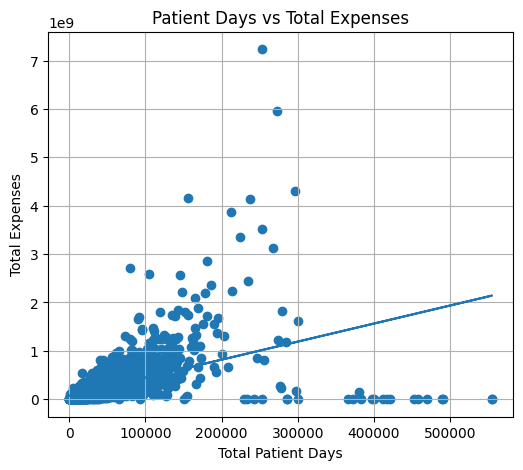

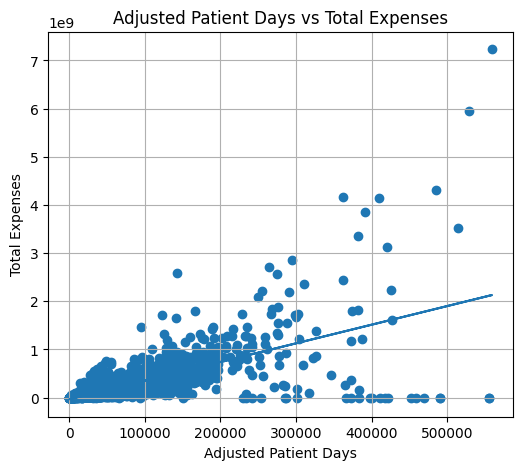

In [ ]:
# Function to plot with regression line
def plot_with_line(x, y, xlabel, title):
    plt.figure(figsize=(6,5))
    plt.scatter(x, y)

    # Fit line
    m, b = np.polyfit(x.dropna(), y.loc[x.dropna().index], 1)
    plt.plot(x, m*x + b)

    plt.xlabel(xlabel)
    plt.ylabel('Total Expenses')
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_with_line(final_df['DAY_TOT'], final_df['Total_Combined_Expenses'],
               'Total Patient Days', 'Patient Days vs Total Expenses')

plot_with_line(final_df['ADJ_PAT_DAYS'], final_df['Total_Combined_Expenses'],
               'Adjusted Patient Days', 'Adjusted Patient Days vs Total Expenses')

In [ ]:
from sklearn.linear_model import LinearRegression
import pandas as pd

def get_stats(x, y):
    df = pd.DataFrame({'x': x, 'y': y}).dropna()
    X = df[['x']]
    y = df['y']

    model = LinearRegression().fit(X, y)

    return {
        'Slope': model.coef_[0],
        'Intercept': model.intercept_,
        'R_squared': model.score(X, y)
    }

# Model 1: Patient Days → FTE
stats_day = get_stats(final_df['DAY_TOT'], final_df['HOSP_FTE'])

# Model 2: Adjusted Patient Days → FTE
stats_adj = get_stats(final_df['ADJ_PAT_DAYS'], final_df['HOSP_FTE'])

# Combine into table
comparison = pd.DataFrame([
    {'Model': 'Patient Days → FTE', **stats_day},
    {'Model': 'Adjusted Patient Days → FTE', **stats_adj}
])

comparison

,Model,Slope,Intercept,R_squared
0,Patient Days → FTE,0.014134,362.248406,0.320631
1,Adjusted Patient Days → FTE,0.013650,41.590157,0.520368


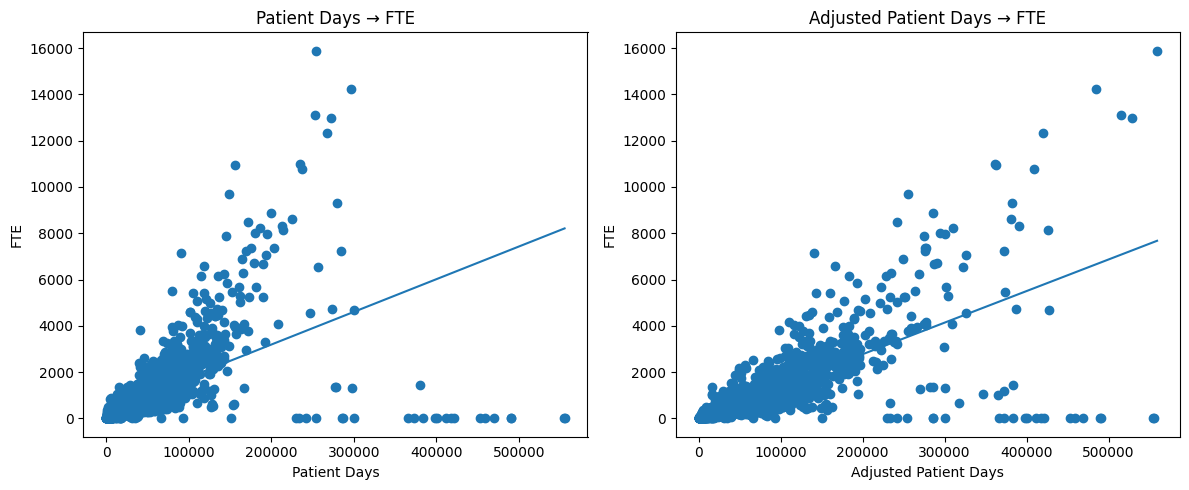

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12,5))

# --- Model 1: Patient Days → FTE ---
df1 = final_df[['DAY_TOT', 'HOSP_FTE']].dropna()

# Fit model
m1, b1 = np.polyfit(df1['DAY_TOT'], df1['HOSP_FTE'], 1)

# Scatter
axes[0].scatter(df1['DAY_TOT'], df1['HOSP_FTE'])

# Line
x_vals = np.linspace(df1['DAY_TOT'].min(), df1['DAY_TOT'].max(), 100)
axes[0].plot(x_vals, m1*x_vals + b1)

axes[0].set_title('Patient Days → FTE')
axes[0].set_xlabel('Patient Days')
axes[0].set_ylabel('FTE')


# --- Model 2: Adjusted Patient Days → FTE ---
df2 = final_df[['ADJ_PAT_DAYS', 'HOSP_FTE']].dropna()

# Fit model
m2, b2 = np.polyfit(df2['ADJ_PAT_DAYS'], df2['HOSP_FTE'], 1)

# Scatter
axes[1].scatter(df2['ADJ_PAT_DAYS'], df2['HOSP_FTE'])

# Line
x_vals = np.linspace(df2['ADJ_PAT_DAYS'].min(), df2['ADJ_PAT_DAYS'].max(), 100)
axes[1].plot(x_vals, m2*x_vals + b2)

axes[1].set_title('Adjusted Patient Days → FTE')
axes[1].set_xlabel('Adjusted Patient Days')
axes[1].set_ylabel('FTE')

plt.tight_layout()
plt.show()

In [ ]:
def flag_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (df[col] < lower) | (df[col] > upper)

# Create flags
final_df['OUTLIER_FTE'] = flag_outliers(final_df, 'HOSP_FTE')
final_df['OUTLIER_DAY'] = flag_outliers(final_df, 'DAY_TOT')
final_df['OUTLIER_ADJ_DAY'] = flag_outliers(final_df, 'ADJ_PAT_DAYS')

# Combine into one flag
final_df['IS_OUTLIER'] = (
    final_df['OUTLIER_FTE'] |
    final_df['OUTLIER_DAY'] |
    final_df['OUTLIER_ADJ_DAY']
)

In [ ]:
outliers = final_df[final_df['IS_OUTLIER']]

outliers[['FAC_NO', 'FAC_NAME', 'YEAR', 'HOSP_FTE', 'DAY_TOT', 'ADJ_PAT_DAYS']].tail(20)

,FAC_NO,FAC_NAME,YEAR,HOSP_FTE,DAY_TOT,ADJ_PAT_DAYS
1645,106190958,METROPOLITAN STATE HOSPITAL,2024,0,300572,300572.000000
1652,106281266,NAPA STATE HOSPITAL,2024,0,400086,400086.000000
1668,106361768,PATTON STATE HOSPITAL,2024,0,490125,490125.000000
1672,106190631,PIH HEALTH WHITTIER HOSPITAL,2024,3330,106415,225529.647178
1692,106370673,RADY CHILDREN'S HOSPITAL - SAN DIEGO,2024,5061,110238,177698.327521
1698,106334487,RIVERSIDE UNIVERSITY HEALTH SYSTEM MEDICAL CENTER,2024,3779,127909,207515.058465
1699,106190796,RONALD REAGAN UCLA MEDICAL CENTER,2024,8021,180564,294892.375221
1711,106410782,SAN MATEO MEDICAL CENTER,2024,1068,114069,346503.850411
1715,106430883,SANTA CLARA VALLEY MEDICAL CENTER,2024,8599,224629,381340.421690
1721,106370744,SCRIPPS MERCY HOSPITAL,2024,3890,160585,258483.689810


In [ ]:
zero_fte_outliers = final_df[
    (final_df['IS_OUTLIER']) & (final_df['HOSP_FTE'] == 0)
]

zero_fte_outliers[['FAC_NO', 'FAC_NAME', 'YEAR', 'HOSP_FTE', 'DAY_TOT', 'ADJ_PAT_DAYS']].head(20)

,FAC_NO,FAC_NAME,YEAR,HOSP_FTE,DAY_TOT,ADJ_PAT_DAYS
9,106400683,ATASCADERO STATE HOSPITAL,2004,0,452428,452428.0
190,106190958,METROPOLITAN STATE HOSPITAL,2004,0,253765,253765.0
199,106281266,NAPA STATE HOSPITAL,2004,0,397916,397916.0
217,106361768,PATTON STATE HOSPITAL,2004,0,490490,490490.0
225,106541123,PORTERVILLE STATE HOSPITAL,2004,0,286425,286425.0
368,106400683,ATASCADERO STATE HOSPITAL,2009,0,372257,372257.0
546,106190958,METROPOLITAN STATE HOSPITAL,2009,0,233575,233575.0
554,106281266,NAPA STATE HOSPITAL,2009,0,417246,417246.0
573,106361768,PATTON STATE HOSPITAL,2009,0,554603,554603.0
581,106541123,PORTERVILLE STATE HOSPITAL,2009,0,229740,229740.0


In [ ]:
print("Total zero-FTE outliers:", len(zero_fte_outliers))

Total zero-FTE outliers: 22


In [ ]:
print("Unique hospitals:", zero_fte_outliers['FAC_NO'].nunique())

Unique hospitals: 5


In [ ]:
zero_fte_outliers['FAC_NAME'].value_counts()

,count
FAC_NAME,
ATASCADERO STATE HOSPITAL,5
METROPOLITAN STATE HOSPITAL,5
NAPA STATE HOSPITAL,5
PATTON STATE HOSPITAL,5
PORTERVILLE STATE HOSPITAL,2


In [ ]:
porterville = final_df[
    final_df['FAC_NAME'].str.contains('PORTERVILLE', case=False, na=False)
]

porterville[['FAC_NO', 'FAC_NAME', 'YEAR', 'HOSP_FTE', 'DAY_TOT', 'ADJ_PAT_DAYS']]

,FAC_NO,FAC_NAME,YEAR,HOSP_FTE,DAY_TOT,ADJ_PAT_DAYS
225,106541123,PORTERVILLE STATE HOSPITAL,2004,0,286425,286425.0
581,106541123,PORTERVILLE STATE HOSPITAL,2009,0,229740,229740.0
947,106541123,PORTERVILLE STATE HOSPITAL,2014,0,150973,150973.0
1315,106541123,PORTERVILLE STATE HOSPITAL,2019,0,93053,93053.0
1677,106541123,PORTERVILLE STATE HOSPITAL,2024,0,65844,65844.0


In [ ]:
zero_fte_outliers['YEAR'].value_counts().sort_index()

,count
YEAR,
2004,5
2009,5
2014,4
2019,4
2024,4


In [ ]:
print("Total outliers:", final_df['IS_OUTLIER'].sum())
print("Percent outliers:", final_df['IS_OUTLIER'].mean())

Total outliers: 146
Percent outliers: 0.08088642659279778


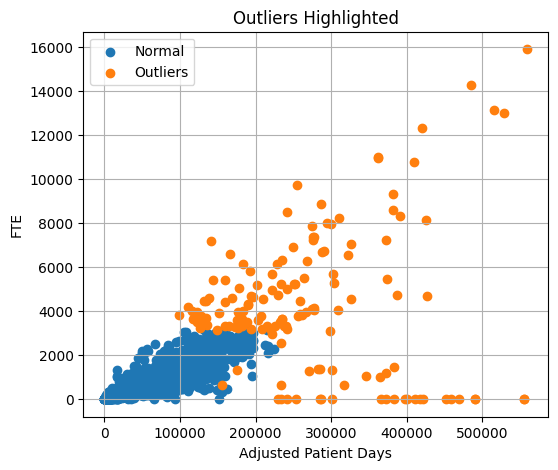

In [ ]:
normal = final_df[~final_df['IS_OUTLIER']]
outliers = final_df[final_df['IS_OUTLIER']]

plt.figure(figsize=(6,5))

# Normal points
plt.scatter(normal['ADJ_PAT_DAYS'], normal['HOSP_FTE'], label='Normal')

# Outliers
plt.scatter(outliers['ADJ_PAT_DAYS'], outliers['HOSP_FTE'], label='Outliers')

plt.xlabel('Adjusted Patient Days')
plt.ylabel('FTE')
plt.title('Outliers Highlighted')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
zero_fte = final_df[final_df['HOSP_FTE'] == 0]
zero_fte[['FAC_NO', 'FAC_NAME', 'YEAR', 'HOSP_FTE', 'DAY_TOT', 'ADJ_PAT_DAYS']]

,FAC_NO,FAC_NAME,YEAR,HOSP_FTE,DAY_TOT,ADJ_PAT_DAYS
9,106400683,ATASCADERO STATE HOSPITAL,2004,0,452428,452428.0
23,106044006,BUTTE COUNTY MENTAL HEALTH - PHF,2004,0,5234,5234.0
76,106094002,EL DORADO COUNTY MENTAL HEALTH-PHF,2004,0,2668,2668.0
135,106015000,KAISER FOUNDATION NORTHERN REGION,2004,0,0,0.0
136,106191300,KAISER FOUNDATION SOUTHERN REGION,2004,0,0,0.0
...,...,...,...,...,...,...
1707,106394003,SAN JOAQUIN - PHF,2024,0,5402,5402.0
1714,106424002,SANTA BARBARA PSYCHIATRIC HEALTH FACILITY,2024,0,5347,5347.0
1723,106124004,SEMPERVIRENS P.H.F.,2024,0,5230,5230.0
1733,106344114,SHRINERS HOSPITAL FOR CHILDREN - NORTHERN CALI...,2024,0,7975,7975.0


In [ ]:
final_df[final_df['IS_OUTLIER']]['TYPE_HOSP'].value_counts()

,count
TYPE_HOSP,
Comparable,100
State,17
COMPARABLE,12
Kaiser,6
STATE,5
LTC Emphasis,5
LTC EMPHASIS,1


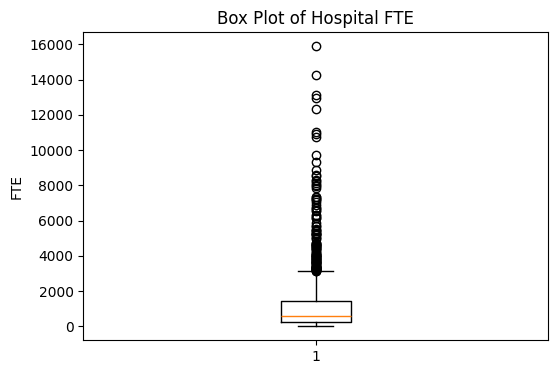

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(final_df['HOSP_FTE'].dropna())

plt.title('Box Plot of Hospital FTE')
plt.ylabel('FTE')
plt.show()

In [ ]:
# Count nulls
print("Null count:", final_df['ADJ_PAT_DAYS'].isna().sum())

# Percentage
print("Null %:", final_df['ADJ_PAT_DAYS'].isna().mean())

Null count: 0
Null %: 0.0


In [ ]:
Q1 = final_df['ADJ_PAT_DAYS'].quantile(0.25)
Q3 = final_df['ADJ_PAT_DAYS'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Flag outliers
final_df['ADJ_OUTLIER'] = (
    (final_df['ADJ_PAT_DAYS'] < lower) |
    (final_df['ADJ_PAT_DAYS'] > upper)
)

In [ ]:
outliers = final_df[final_df['ADJ_OUTLIER']]

outliers[[
    'FAC_NO', 'FAC_NAME', 'YEAR',
    'ADJ_PAT_DAYS', 'DAY_TOT', 'HOSP_FTE'
]].sort_values(by='ADJ_PAT_DAYS', ascending=False).head(15)

,FAC_NO,FAC_NAME,YEAR,ADJ_PAT_DAYS,DAY_TOT,HOSP_FTE
1753,106430905,STANFORD HEALTH CARE,2024,559186.756968,253755,15890
940,106361768,PATTON STATE HOSPITAL,2014,555219.000000,555219,0
573,106361768,PATTON STATE HOSPITAL,2009,554603.000000,554603,0
1785,106381154,UCSF MEDICAL CENTER,2024,528957.129275,272474,12973
1788,106370782,UNIVERSITY OF CALIFORNIA SAN DIEGO MEDICAL CENTER,2024,514752.939043,253495,13119
217,106361768,PATTON STATE HOSPITAL,2004,490490.000000,490490,0
1668,106361768,PATTON STATE HOSPITAL,2024,490125.000000,490125,0
1486,106190555,CEDARS-SINAI MEDICAL CENTER,2024,484435.075205,296716,14246
1307,106361768,PATTON STATE HOSPITAL,2019,469375.000000,469375,0
1290,106281266,NAPA STATE HOSPITAL,2019,458631.000000,458631,0


In [ ]:
final_df['ADJ_PAT_DAYS'].describe()

,ADJ_PAT_DAYS
count,1805.000000
mean,77461.308957
std,78359.454315
min,0.000000
25%,25552.783933
50%,52803.654169
75%,106136.535124
max,559186.756968


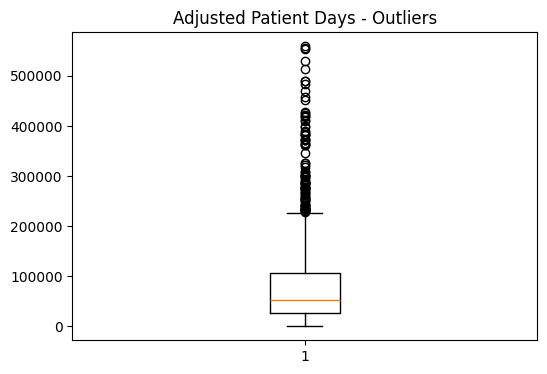

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(final_df['ADJ_PAT_DAYS'].dropna())
plt.title('Adjusted Patient Days - Outliers')
plt.show()

In [ ]:
#dropping 0 fte rows
df_analysis = final_df[final_df['HOSP_FTE'] > 0]

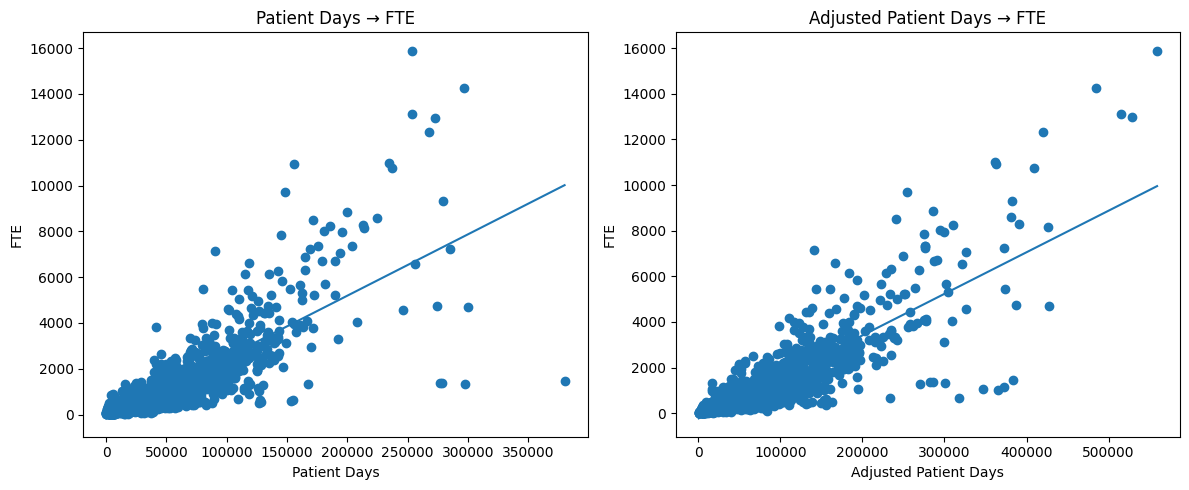

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12,5))

# --- Model 1: Patient Days → FTE ---
df1 = df_analysis[['DAY_TOT', 'HOSP_FTE']].dropna()

# Fit model
m1, b1 = np.polyfit(df1['DAY_TOT'], df1['HOSP_FTE'], 1)

# Scatter
axes[0].scatter(df1['DAY_TOT'], df1['HOSP_FTE'])

# Line
x_vals1 = np.linspace(df1['DAY_TOT'].min(), df1['DAY_TOT'].max(), 100)
axes[0].plot(x_vals1, m1*x_vals1 + b1)

axes[0].set_title('Patient Days → FTE')
axes[0].set_xlabel('Patient Days')
axes[0].set_ylabel('FTE')


# --- Model 2: Adjusted Patient Days → FTE ---
df2 = df_analysis[['ADJ_PAT_DAYS', 'HOSP_FTE']].dropna()

# Fit model
m2, b2 = np.polyfit(df2['ADJ_PAT_DAYS'], df2['HOSP_FTE'], 1)

# Scatter
axes[1].scatter(df2['ADJ_PAT_DAYS'], df2['HOSP_FTE'])

# Line
x_vals2 = np.linspace(df2['ADJ_PAT_DAYS'].min(), df2['ADJ_PAT_DAYS'].max(), 100)
axes[1].plot(x_vals2, m2*x_vals2 + b2)

axes[1].set_title('Adjusted Patient Days → FTE')
axes[1].set_xlabel('Adjusted Patient Days')
axes[1].set_ylabel('FTE')

plt.tight_layout()
plt.show()

In [ ]:
# Model 1: Patient Days → FTE
stats_day = get_stats(df_analysis['DAY_TOT'], df_analysis['HOSP_FTE'])

# Model 2: Adjusted Patient Days → FTE
stats_adj = get_stats(df_analysis['ADJ_PAT_DAYS'], df_analysis['HOSP_FTE'])

# Combine into table
comparison = pd.DataFrame([
    {'Model': 'Patient Days → FTE', **stats_day},
    {'Model': 'Adjusted Patient Days → FTE', **stats_adj}
])

comparison

,Model,Slope,Intercept,R_squared
0,Patient Days → FTE,0.026806,-170.971906,0.662766
1,Adjusted Patient Days → FTE,0.018215,-230.684696,0.727702


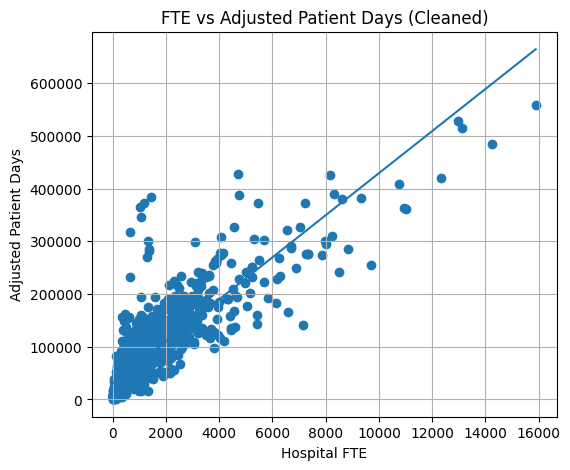

Slope (Adj Days per FTE): 39.95143289653941
R²: 0.7277018162128698


In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Prepare data
df = df_analysis[['HOSP_FTE', 'ADJ_PAT_DAYS']].dropna()

X = df[['HOSP_FTE']]
y = df['ADJ_PAT_DAYS']

model = LinearRegression().fit(X, y)

slope = model.coef_[0]
intercept = model.intercept_

# Plot
plt.figure(figsize=(6,5))
plt.scatter(df['HOSP_FTE'], df['ADJ_PAT_DAYS'])

x_vals = np.linspace(df['HOSP_FTE'].min(), df['HOSP_FTE'].max(), 100)
y_vals = slope * x_vals + intercept
plt.plot(x_vals, y_vals)

plt.xlabel('Hospital FTE')
plt.ylabel('Adjusted Patient Days')
plt.title('FTE vs Adjusted Patient Days (Cleaned)')
plt.grid(True)
plt.show()

print("Slope (Adj Days per FTE):", slope)
print("R²:", model.score(X, y))

In [ ]:
(df_analysis['ADJ_PAT_DAYS'] / df_analysis['HOSP_FTE']).describe()

,0
count,1721.000000
mean,94.323130
std,70.787476
min,11.941372
25%,57.581894
50%,74.598394
75%,102.459964
max,870.725222


In [ ]:
from sklearn.linear_model import LinearRegression
import pandas as pd

df = final_df[['HOSP_FTE', 'ADJ_PAT_DAYS']].dropna()

X = df[['ADJ_PAT_DAYS']]
y = df['HOSP_FTE']

model = LinearRegression().fit(X, y)

slope = model.coef_[0]
intercept = model.intercept_
r2 = model.score(X, y)

print("Slope (FTE per Adj Day):", slope)
print("R²:", r2)

Slope (FTE per Adj Day): 0.013650441083230713
R²: 0.5203676296848788


In [ ]:
df_analysis['ADJ_RATIO'] = df_analysis['ADJ_PAT_DAYS'] / df_analysis['DAY_TOT']

/tmp/ipykernel_57841/1271730160.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_analysis['ADJ_RATIO'] = df_analysis['ADJ_PAT_DAYS'] / df_analysis['DAY_TOT']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

def slr_plot(df, x_col, y_col, title=None, xlabel=None, ylabel=None, show=True):
    # Keep only needed columns and drop missing values
    data = df[[x_col, y_col]].dropna().copy()

    if data.empty:
        raise ValueError(f"No valid data after dropping NaNs for {x_col} and {y_col}.")

    X = data[[x_col]]
    y = data[y_col]

    # Fit model
    model = LinearRegression()
    model.fit(X, y)

    slope = float(model.coef_[0])
    intercept = float(model.intercept_)
    r2 = float(model.score(X, y))

    # Plot
    plt.figure(figsize=(7, 5))
    plt.scatter(data[x_col], data[y_col], alpha=0.6)

    x_vals = np.linspace(data[x_col].min(), data[x_col].max(), 100)
    y_vals = slope * x_vals + intercept
    plt.plot(x_vals, y_vals)

    plt.title(title if title else f"{y_col} vs {x_col}")
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.grid(True)

    plt.text(
        0.05, 0.95,
        f"Slope = {slope:.4f}\nIntercept = {intercept:.4f}\nR² = {r2:.4f}",
        transform=plt.gca().transAxes,
        va="top"
    )

    if show:
        plt.show()

    results = {
        "Model": f"{y_col} ~ {x_col}",
        "Slope": slope,
        "Intercept": intercept,
        "R_squared": r2,
        "n": len(data)
    }

    print(results)
    return results, model

In [ ]:
stats_emp_adj, model_emp_adj = slr_plot(
    df_analysis,
    x_col="ADJ_PAT_DAYS",
    y_col="Employee_Cost",
    title="Employee Cost vs Adjusted Patient Days",
    xlabel="Adjusted Patient Days",
    ylabel="Employee Cost"
)

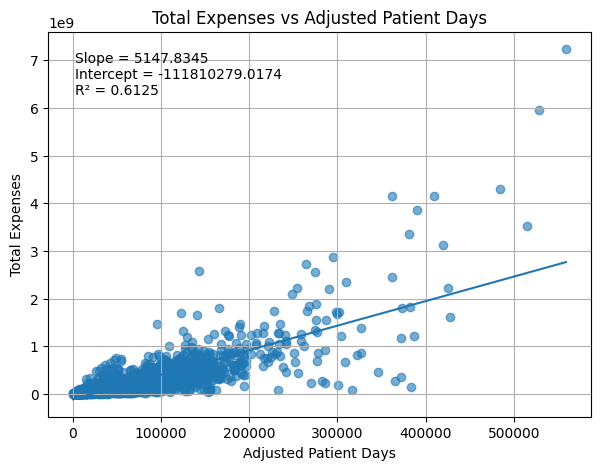

{'Model': 'Total_Combined_Expenses ~ ADJ_PAT_DAYS', 'Slope': 5147.834549539028, 'Intercept': -111810279.01736438, 'R_squared': 0.6124748136290088, 'n': 1721}


In [ ]:
stats_tot_adj, model_tot_adj = slr_plot(df_analysis, "ADJ_PAT_DAYS", "Total_Combined_Expenses", title="Total Expenses vs Adjusted Patient Days",
    xlabel="Adjusted Patient Days",
    ylabel="Total Expenses")

In [ ]:
comparison = pd.DataFrame([
    {
        'Model': 'Employee Cost ~ Adjusted Patient Days',
        'Slope ($/Adj Day)': stats_emp_adj['Slope'],
        'Intercept ($)': stats_emp_adj['Intercept'],
        'R²': stats_emp_adj['R_squared']
    },
    {
        'Model': 'Total Expenses ~ Adjusted Patient Days',
        'Slope ($/Adj Day)': stats_tot_adj['Slope'],
        'Intercept ($)': stats_tot_adj['Intercept'],
        'R²': stats_tot_adj['R_squared']
    }
])

# Round for cleaner display
comparison = comparison.round({
    'Slope ($/Adj Day)': 2,
    'Intercept ($)': 0,
    'R²': 3
})

comparison

,Model,Slope ($/Adj Day),Intercept ($),R²
0,Employee Cost ~ Adjusted Patient Days,2593.75,-68704040.0,0.624
1,Total Expenses ~ Adjusted Patient Days,5147.83,-111810279.0,0.612


In [ ]:
stats_patient = get_stats(df_analysis['ADJ_PAT_DAYS'], df_analysis['Patient_Expenses'])
stats_overhead = get_stats(df_analysis['ADJ_PAT_DAYS'], df_analysis['Overhead_Expenses'])

comparison = pd.DataFrame([
    {'Model': 'Patient Expenses ~ Adjusted Patient Days', **stats_patient},
    {'Model': 'Overhead Expenses ~ Adjusted Patient Days', **stats_overhead}
])

comparison

,Model,Slope,Intercept,R_squared
0,Patient Expenses ~ Adjusted Patient Days,3122.743743,-6.972613e+07,0.590029
1,Overhead Expenses ~ Adjusted Patient Days,2025.090806,-4.208415e+07,0.611896


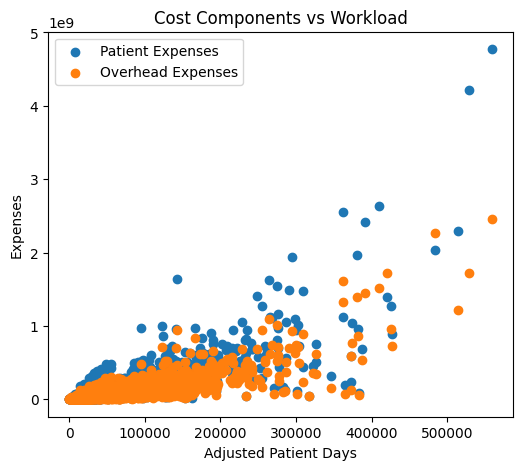

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.scatter(df_analysis['ADJ_PAT_DAYS'], df_analysis['Patient_Expenses'], label='Patient Expenses')
plt.scatter(df_analysis['ADJ_PAT_DAYS'], df_analysis['Overhead_Expenses'], label='Overhead Expenses')

plt.xlabel('Adjusted Patient Days')
plt.ylabel('Expenses')
plt.title('Cost Components vs Workload')
plt.legend()
plt.show()

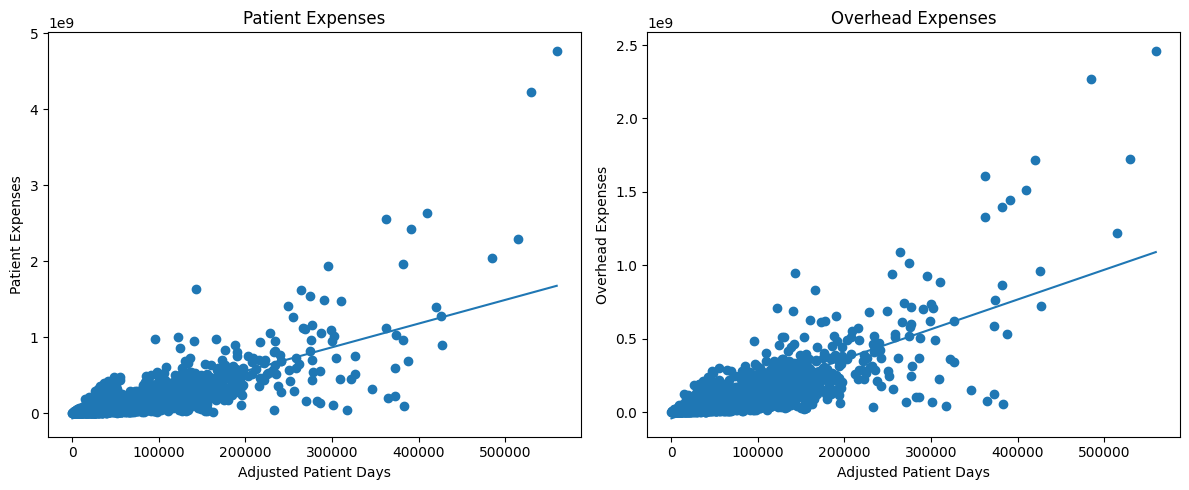

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Patient Expenses
df1 = df_analysis[['ADJ_PAT_DAYS', 'Patient_Expenses']].dropna()
m1, b1 = np.polyfit(df1['ADJ_PAT_DAYS'], df1['Patient_Expenses'], 1)

axes[0].scatter(df1['ADJ_PAT_DAYS'], df1['Patient_Expenses'])
x_vals = np.linspace(df1['ADJ_PAT_DAYS'].min(), df1['ADJ_PAT_DAYS'].max(), 100)
axes[0].plot(x_vals, m1*x_vals + b1)
axes[0].set_title('Patient Expenses')
axes[0].set_xlabel('Adjusted Patient Days')
axes[0].set_ylabel('Patient Expenses')


# Overhead Expenses
df2 = df_analysis[['ADJ_PAT_DAYS', 'Overhead_Expenses']].dropna()
m2, b2 = np.polyfit(df2['ADJ_PAT_DAYS'], df2['Overhead_Expenses'], 1)

axes[1].scatter(df2['ADJ_PAT_DAYS'], df2['Overhead_Expenses'])
x_vals = np.linspace(df2['ADJ_PAT_DAYS'].min(), df2['ADJ_PAT_DAYS'].max(), 100)
axes[1].plot(x_vals, m2*x_vals + b2)
axes[1].set_title('Overhead Expenses')
axes[1].set_xlabel('Adjusted Patient Days')
axes[1].set_ylabel('Overhead Expenses')

plt.tight_layout()
plt.show()

In [ ]:
Q1 = final_df['HOSP_FTE'].quantile(0.25)
Q3 = final_df['HOSP_FTE'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

fte_outliers = final_df[
    (final_df['HOSP_FTE'] < lower) |
    (final_df['HOSP_FTE'] > upper)
]

fte_outliers[['FAC_NAME', 'YEAR', 'HOSP_FTE']].head(20)

,FAC_NAME,YEAR,HOSP_FTE
28,CEDARS-SINAI MEDICAL CENTER,2004,7237
53,COMMUNITY MEDICAL CENTER - FRESNO,2004,3769
154,LAC/USC MEDICAL CENTER,2004,6553
160,LOMA LINDA UNIVERSITY MEDICAL CENTER,2004,5225
260,SANTA CLARA VALLEY MEDICAL CENTER,2004,4345
308,STANFORD UNIVERSITY HOSPITAL,2004,4632
321,SUTTER MEDICAL CENTER - SACRAMENTO,2004,3318
336,UCLA MEDICAL CENTER,2004,5232
338,UCSF MEDICAL CENTER,2004,5013
340,UNIVERSITY OF CALIFORNIA DAVIS MED CTR,2004,5833


In [ ]:
print("Lower bound:", lower)

Lower bound: -1483.5


In [ ]:
print("Total FTE outliers:", len(fte_outliers))

Total FTE outliers: 109


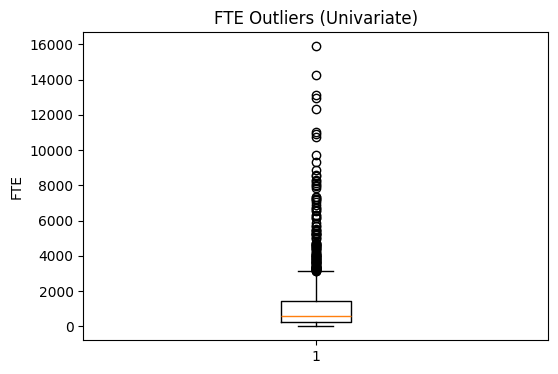

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(final_df['HOSP_FTE'].dropna())

plt.title('FTE Outliers (Univariate)')
plt.ylabel('FTE')
plt.show()

In [ ]:
zero_fte = final_df[final_df['HOSP_FTE'] == 0]

In [ ]:
zero_fte['TYPE_HOSP'].value_counts()

,count
TYPE_HOSP,
PHF,43
State,20
Kaiser,8
Other Non-Comparable,5
STATE,5
KAISER,2
OTHER NON-COMPARABLE,1


In [ ]:
zero_fte['TYPE_CARE'].value_counts()

,count
TYPE_CARE,
Psychiatric,39
Specialty,16
PSYCHIATRIC,13
General,9
Children,3
GENERAL,2
CHILDRENS,1
Childrens,1


In [ ]:
final_df['TYPE_CARE_CLEAN'] = final_df['TYPE_CARE'].str.upper()

zero_fte['TYPE_CARE_CLEAN'] = zero_fte['TYPE_CARE'].str.upper()



/tmp/ipykernel_57841/1746207145.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  zero_fte['TYPE_CARE_CLEAN'] = zero_fte['TYPE_CARE'].str.upper()


,count
TYPE_CARE_CLEAN,
PSYCHIATRIC,52
SPECIALTY,16
GENERAL,11
CHILDREN,3
CHILDRENS,2


In [ ]:
zero_fte['TYPE_CARE_CLEAN'].value_counts()

,count
TYPE_CARE_CLEAN,
PSYCHIATRIC,52
SPECIALTY,16
GENERAL,11
CHILDREN,3
CHILDRENS,2


In [ ]:
zero_fte[['FAC_NO', 'FAC_NAME', 'TYPE_HOSP']].drop_duplicates()

,FAC_NO,FAC_NAME,TYPE_HOSP
9,106400683,ATASCADERO STATE HOSPITAL,STATE
23,106044006,BUTTE COUNTY MENTAL HEALTH - PHF,PHF
76,106094002,EL DORADO COUNTY MENTAL HEALTH-PHF,PHF
135,106015000,KAISER FOUNDATION NORTHERN REGION,KAISER
136,106191300,KAISER FOUNDATION SOUTHERN REGION,KAISER
170,106244027,MARIE GREEN PSYCHIATRIC CENTER -PHF,PHF
190,106190958,METROPOLITAN STATE HOSPITAL,STATE
199,106281266,NAPA STATE HOSPITAL,STATE
217,106361768,PATTON STATE HOSPITAL,STATE
225,106541123,PORTERVILLE STATE HOSPITAL,STATE


In [ ]:
zero_fte_unique = zero_fte[['FAC_NO', 'FAC_NAME', 'TYPE_HOSP']].drop_duplicates()

zero_fte_unique['TYPE_HOSP'].value_counts()

,count
TYPE_HOSP,
PHF,22
STATE,5
State,5
Other Non-Comparable,3
KAISER,2
Kaiser,2
OTHER NON-COMPARABLE,1


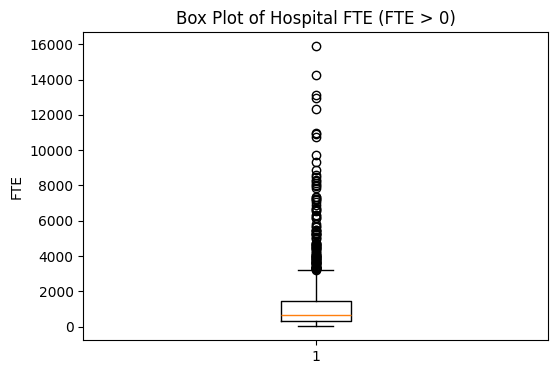

In [ ]:
import matplotlib.pyplot as plt

# Filter out FTE = 0
df_plot = final_df[final_df['HOSP_FTE'] > 0]

plt.figure(figsize=(6,4))
plt.boxplot(df_plot['HOSP_FTE'].dropna())

plt.title('Box Plot of Hospital FTE (FTE > 0)')
plt.ylabel('FTE')
plt.show()

In [ ]:
print("Descriptive statistics for HOSP_FTE (FTE > 0):")
display(df_plot['HOSP_FTE'].describe())

Descriptive statistics for HOSP_FTE (FTE > 0):


,HOSP_FTE
count,1721.000000
mean,1152.610691
std,1498.070951
min,17.000000
25%,294.000000
50%,662.000000
75%,1464.000000
max,15890.000000


In [ ]:
cols = [
    'HOSP_FTE',
    'DAY_TOT',
    'ADJ_PAT_DAYS',
    'Employee_Cost',
    'Patient_Expenses',
    'Overhead_Expenses',
    'AVG_WAGE'
]

corr = df_analysis[cols].corr()

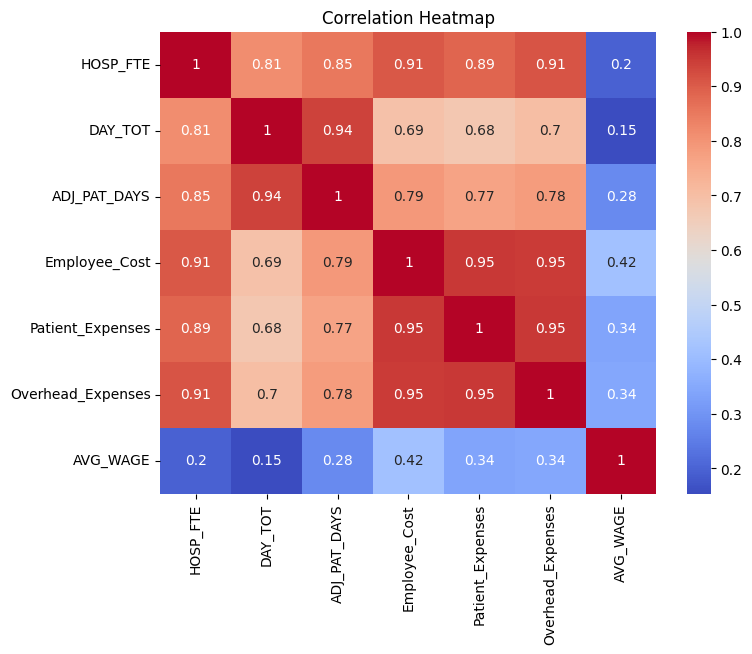

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
final_df.to_csv('final_hospital_data.csv', index=False)
print("final_hospital_data.csv saved successfully!")

final_hospital_data.csv saved successfully!


In [ ]:
from pathlib import Path

# Define the target folder path
output_folder = Path("/content/drive/MyDrive/Hospital_Data/GN_data")
output_folder.mkdir(parents=True, exist_ok=True)

# Define the output file path
output_file_path = output_folder / "merged_hospital_data.csv"

# Save the DataFrame to CSV
final_df.to_csv(output_file_path, index=False)

print(f"DataFrame saved to: {output_file_path}")

DataFrame saved to: /content/drive/MyDrive/Hospital_Data/GN_data/merged_hospital_data.csv
